# 🎲 Yahtzee — Simulación de Montecarlo

## Implementación paso a paso en Python / Google Colab

Este notebook implementa el algoritmo definido en la actividad:

1. Crear dos jugadores con tarjetas vacías.
2. Ejecutar 13 rondas.
3. Cada jugador realiza un turno.
4. Lanzar cinco dados.
5. Después del primer y segundo lanzamiento, aplicar la estrategia para conservar dados y relanzar los demás.
6. Evaluar la combinación y seleccionar una categoría disponible.
7. Aplicar las reglas de puntuación y Joker cuando corresponda.
8. Registrar los puntos.
9. Al terminar las 13 rondas, calcular bonificaciones y puntuaciones finales.
10. Comparar los resultados y determinar ganador o empate.
11. Repetir la partida mediante Montecarlo con 1.000 y 10.000 experimentos.

**Fuente de reglas:** documento de la actividad suministrado por el estudiante.

## 0. Decisiones de implementación tomadas del documento

La actividad define una estrategia heurística, no una estrategia óptima.

Se utilizará:

- **Máximo 3 lanzamientos por turno.**
- La estrategia se consulta después del lanzamiento 1 y después del lanzamiento 2.
- Si se obtiene Yahtzee, se conservan los cinco dados.
- Si se obtiene escalera grande o full house y la categoría está disponible, se conservan.
- Se priorizan cuatro consecutivos, cuatro iguales, tres iguales y finalmente el grupo repetido más numeroso.
- Para puntuar, se busca la mayor puntuación inmediata.
- En empate se prioriza una categoría superior mientras se intenta alcanzar 63 puntos.
- Si continúa el empate, se utiliza un orden fijo.

**Importante sobre Joker:** la regla Joker se aplica solamente cuando el Yahtzee es **adicional**, es decir, cuando la categoría Yahtzee ya había sido registrada con 50 puntos. Si Yahtzee fue registrada previamente con 0, no se concede la bonificación de 100, aunque se aplican las reglas Joker indicadas en el documento.

```markdown
### Explicación de la Semilla Aleatoria (`SEED`)

En programación, los números generados por funciones como `random.randint` no son verdaderamente aleatorios, sino **pseudoaleatorios**. Esto significa que son calculados mediante un algoritmo matemático determinista a partir de un valor inicial conocido como **semilla** (o `SEED`).

#### ¿Qué función cumple `SEED` en este programa?
1. **Reproducibilidad:** Al establecer una semilla fija (`SEED = 20261017`), nos aseguramos de que el generador pseudoaleatorio produzca exactamente la misma secuencia de números cada vez que se ejecute el notebook. Esto permite que los lanzamientos de dados, los turnos y el resultado final de la partida sean idénticos en cualquier computadora.
2. **Validación y Auditoría:** Permite que otros desarrolladores, evaluadores o tú mismo ejecuten el código y obtengan exactamente las mismas métricas, facilitando la detección de errores y la verificación de que las reglas del juego se aplican correctamente.
3. **Consistencia en Montecarlo:** En simulaciones estadísticas pesadas (como los experimentos de 1.000 y 10.000 partidas), el uso de semillas controladas garantiza que las conclusiones del estudio estadístico sean estables y verificables en fases posteriores.
```

In [ ]:
import random
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CATEGORIAS_SUPERIORES = ["Unos", "Doses", "Treses", "Cuatros", "Cincos", "Seises"]
CATEGORIAS_INFERIORES = [
    "Tres iguales", "Cuatro iguales", "Full house",
    "Escalera pequeña", "Escalera grande", "Yahtzee", "Oportunidad"
]
CATEGORIAS = CATEGORIAS_SUPERIORES + CATEGORIAS_INFERIORES
ORDEN_CATEGORIAS = {categoria: i for i, categoria in enumerate(CATEGORIAS)}

SEED = 20261017
random.seed(SEED)

print("Categorías:", len(CATEGORIAS))
print(CATEGORIAS)

Categorías: 13
['Unos', 'Doses', 'Treses', 'Cuatros', 'Cincos', 'Seises', 'Tres iguales', 'Cuatro iguales', 'Full house', 'Escalera pequeña', 'Escalera grande', 'Yahtzee', 'Oportunidad']


## 1. Generador de dados

Cada lanzamiento genera valores enteros entre 1 y 6. La actividad establece una distribución uniforme: cada cara tiene probabilidad 1/6.

Esta función corresponde al componente **Generador de dados**.

In [ ]:
def lanzar_cinco_dados():
    # Genera una lista de 5 números enteros aleatorios entre 1 y 6 (inclusive).
    # Representa el lanzamiento inicial de un turno utilizando una distribución uniforme (probabilidad 1/6).
    return [random.randint(1, 6) for _ in range(5)]

def volver_a_lanzar_no_conservados(dados, indices_conservar):
    # Convierte la lista de índices a conservar en un conjunto (set) para búsquedas rápidas de O(1).
    indices_conservar = set(indices_conservar)
    # Realiza una copia superficial de la lista original de dados para no modificarla directamente.
    nuevos_dados = dados.copy()

    # Itera sobre los 5 dados (posiciones 0 a 4).
    for i in range(5):
        # Si la posición actual 'i' no está en el conjunto de dados conservados, se vuelve a lanzar.
        if i not in indices_conservar:
            nuevos_dados[i] = random.randint(1, 6)

    # Retorna el nuevo estado de la mano de dados después del relanzamiento.
    return nuevos_dados

# Demostración del primer lanzamiento para validación manual.
dados = lanzar_cinco_dados()
print("Primer lanzamiento:", dados)

# Validaciones estructurales básicas (Aseguran que siempre haya 5 dados y con valores correctos del 1 al 6).
assert len(dados) == 5
assert all(1 <= d <= 6 for d in dados)

Primer lanzamiento: [3, 1, 4, 2, 6]


## 2. Identificación de combinaciones

Aquí no asignamos puntos todavía. Solamente determinamos qué combinaciones aparecen en los dados.

Esto permite cumplir una condición importante de la actividad: distinguir entre:

- combinación **observada durante los lanzamientos**;
- categoría **finalmente utilizada para puntuar**.

In [ ]:
def es_escalera_pequena(dados):
    # Convierte la lista de dados a un conjunto para eliminar duplicados.
    valores = set(dados)
    # Retorna True si cualquiera de las tres secuencias posibles de 4 números consecutivos es un subconjunto de los dados.
    return (
        {1, 2, 3, 4}.issubset(valores)
        or {2, 3, 4, 5}.issubset(valores)
        or {3, 4, 5, 6}.issubset(valores)
    )

def es_escalera_grande(dados):
    # Convierte a conjunto. Una escalera grande requiere exactamente los 5 valores consecutivos sin repetir.
    valores = set(dados)
    # Compara si el conjunto es exactamente idéntico a {1,2,3,4,5} o {2,3,4,5,6}.
    return valores == {1, 2, 3, 4, 5} or valores == {2, 3, 4, 5, 6}

def es_full_house(dados):
    # Obtiene las frecuencias de aparición de cada número y las ordena.
    # Si los dados forman un Full House, las frecuencias deben ser exactamente 2 y 3 (ej. tres 5s y dos 2s).
    return sorted(Counter(dados).values()) == [2, 3]

def es_yahtzee(dados):
    # Si la longitud del conjunto de valores es 1, significa que los 5 dados tienen el mismo número.
    return len(set(dados)) == 1

def tiene_tres_iguales(dados):
    # Verifica si el número más repetido aparece al menos 3 veces.
    return max(Counter(dados).values()) >= 3

def tiene_cuatro_iguales(dados):
    # Verifica si el número más repetido aparece al menos 4 veces.
    return max(Counter(dados).values()) >= 4

def identificar_combinaciones(dados):
    # Inicializa una lista vacía para almacenar los nombres de todas las combinaciones presentes en la mano.
    combinaciones = []

    # Evalúa de forma independiente cada patrón para poblar las combinaciones observadas durante el turno.
    if tiene_tres_iguales(dados):
        combinaciones.append("Tres iguales")

    if tiene_cuatro_iguales(dados):
        combinaciones.append("Cuatro iguales")

    if es_full_house(dados):
        combinaciones.append("Full house")

    if es_escalera_pequena(dados):
        combinaciones.append("Escalera pequeña")

    if es_escalera_grande(dados):
        combinaciones.append("Escalera grande")

    if es_yahtzee(dados):
        combinaciones.append("Yahtzee")

    # Devuelve la lista de combinaciones detectadas.
    return combinaciones

## 3. Motor de puntuación

Implementamos exactamente las categorías indicadas en la actividad:

- Superiores: suma de los dados del valor correspondiente.
- Tres iguales: suma de los cinco dados si existen al menos tres iguales.
- Cuatro iguales: suma de los cinco dados si existen al menos cuatro iguales.
- Full house: 25.
- Escalera pequeña: 30.
- Escalera grande: 40.
- Yahtzee: 50.
- Oportunidad: suma de los cinco dados.

In [ ]:
def puntuar_categoria(dados, categoria):
    # Calcula la suma total de todos los dados en la mano
    total = sum(dados)
    # Obtiene la frecuencia de aparición de cada valor de cara
    conteos = Counter(dados)

    # --- SECCIÓN SUPERIOR ---
    # Si se evalúa una categoría de la sección superior (Unos a Seises)
    if categoria in CATEGORIAS_SUPERIORES:
        # Determina el valor numérico objetivo (ej. "Unos" -> 1, "Doses" -> 2...)
        valor = CATEGORIAS_SUPERIORES.index(categoria) + 1
        # Suma únicamente los dados que coinciden con ese valor de cara específico
        return sum(dado for dado in dados if dado == valor)

    # --- SECCIÓN INFERIOR ---
    if categoria == "Tres iguales":
        # Suma todos los dados si al menos tres son idénticos; de lo contrario, 0 puntos
        return total if max(conteos.values()) >= 3 else 0

    if categoria == "Cuatro iguales":
        # Suma todos los dados si al menos cuatro son idénticos; de lo contrario, 0 puntos
        return total if max(conteos.values()) >= 4 else 0

    if categoria == "Full house":
        # Puntuación fija de 25 puntos si se cumple el criterio de Full House
        return 25 if es_full_house(dados) else 0

    if categoria == "Escalera pequeña":
        # Puntuación fija de 30 puntos si se tiene una escalera pequeña (secuencia de 4 consecutivos)
        return 30 if es_escalera_pequena(dados) else 0

    if categoria == "Escalera grande":
        # Puntuación fija de 40 puntos si se tiene una escalera grande (secuencia de 5 consecutivos)
        return 40 if es_escalera_grande(dados) else 0

    if categoria == "Yahtzee":
        # Puntuación fija de 50 puntos si los cinco dados son idénticos
        return 50 if es_yahtzee(dados) else 0

    if categoria == "Oportunidad":
        # Suma incondicional de los cinco dados
        return total

    raise ValueError("Categoría no reconocida")

# Casos de prueba del documento
casos = [
    ([1, 1, 3, 4, 6], "Unos", 2),
    ([3, 3, 3, 2, 6], "Tres iguales", 17),
    ([2, 2, 2, 5, 5], "Full house", 25),
    ([1, 2, 3, 4, 6], "Escalera pequeña", 30),
    ([2, 3, 4, 5, 6], "Escalera grande", 40),
    ([4, 4, 4, 4, 4], "Yahtzee", 50),
]

for dados, categoria, esperado in casos:
    obtenido = puntuar_categoria(dados, categoria)
    print(dados, "→", categoria, "=", obtenido)
    assert obtenido == esperado

print("✓ Pruebas de puntuación superadas")

[1, 1, 3, 4, 6] → Unos = 2
[3, 3, 3, 2, 6] → Tres iguales = 17
[2, 2, 2, 5, 5] → Full house = 25
[1, 2, 3, 4, 6] → Escalera pequeña = 30
[2, 3, 4, 5, 6] → Escalera grande = 40
[4, 4, 4, 4, 4] → Yahtzee = 50
✓ Pruebas de puntuación superadas


## 4. Estructura del jugador

La tarjeta utiliza:

- `None` → categoría todavía disponible.
- `0` → categoría utilizada y obtuvo cero.
- cualquier otro número → categoría utilizada con esa puntuación.

Esta distinción es necesaria porque una categoría con cero puntos **no puede volver a utilizarse**.

In [ ]:
class Jugador:
    def __init__(self, nombre):
        # Guarda el nombre identificador del jugador (ej. "Jugador 1").
        self.nombre = nombre
        # Inicializa la tarjeta de juego con valor None en cada categoría.
        # None significa disponible. 0 representa que se tachó/utilizó obteniendo 0 puntos.
        self.tarjeta = {categoria: None for categoria in CATEGORIAS}

        # Variables de control para las bonificaciones especiales.
        self.bonificacion_superior = 0
        self.yahtzees_adicionales = 0
        self.bonificacion_yahtzee = 0

        # Historial de turnos detallado para análisis y auditoría.
        self.historial_turnos = []

    def categorias_disponibles(self):
        # Retorna únicamente las categorías donde el valor almacenado sigue siendo None.
        return [c for c, p in self.tarjeta.items() if p is None]

    def subtotal_superior(self):
        # Suma los valores de la sección superior (Unos a Seises), convirtiendo None a 0.
        return sum(self.tarjeta[c] or 0 for c in CATEGORIAS_SUPERIORES)

    def subtotal_inferior(self):
        # Suma los valores de la sección inferior (sin incluir las bonificaciones de Yahtzee adicional).
        return sum(self.tarjeta[c] or 0 for c in CATEGORIAS_INFERIORES)

    def calcular_puntuacion_final(self):
        # Regla: Si el subtotal de la sección superior es igual o mayor a 63 puntos, se otorga un bono de 35.
        self.bonificacion_superior = (
            35 if self.subtotal_superior() >= 63 else 0
        )

        # La puntuación final es la suma de: Secc. Superior + Bono Superior + Secc. Inferior + Bonos Yahtzee.
        return (
            self.subtotal_superior()
            + self.bonificacion_superior
            + self.subtotal_inferior()
            + self.bonificacion_yahtzee
        )

## 5. Estrategia para conservar dados

La estrategia sigue el orden descrito en el documento.

El resultado de esta función es:

- índices de dados que se conservan;
- indicador de si se puede finalizar el turno sin relanzar.

In [ ]:
def indices_del_valor(dados, valor):
    # Retorna las posiciones físicas (índices 0 a 4) en las que aparece el valor especificado.
    return [i for i, dado in enumerate(dados) if dado == valor]

def indices_grupo_mas_numeroso(dados):
    # Cuenta cuántas veces aparece cada cara del dado en la mano.
    conteos = Counter(dados)
    # Determina cuál es la frecuencia máxima registrada en la mano.
    mayor_cantidad = max(conteos.values())

    # Filtra cuáles números alcanzaron esa frecuencia máxima (para manejar empates).
    # En empate se conserva el grupo del valor más alto.
    valores = [valor for valor, cantidad in conteos.items()
               if cantidad == mayor_cantidad]

    # Criterio de desempate de la actividad: se conserva el grupo con el valor numérico más alto.
    valor_elegido = max(valores)
    return indices_del_valor(dados, valor_elegido)

def indices_cuatro_consecutivos(dados):
    # Secuencias posibles para formar una Escalera Pequeña.
    secuencias = [
        [1, 2, 3, 4],
        [2, 3, 4, 5],
        [3, 4, 5, 6]
    ]

    for secuencia in secuencias:
        # Obtiene la intersección de valores de la mano con la secuencia candidata.
        presentes = set(dados).intersection(secuencia)

        # Si la intersección tiene exactamente 4 elementos, hemos hallado la escalera pequeña.
        if len(presentes) == 4:
            indices = []
            usados = set()

            # Mapea los valores hacia sus respectivos índices físicos de forma única (evita duplicados).
            for i, dado in enumerate(dados):
                if dado in presentes and dado not in usados:
                    indices.append(i)
                    usados.add(dado)

            if len(indices) == 4:
                return indices

    return None

def aplicar_estrategia_conservar(dados, jugador):
    # 1. Yahtzee
    if es_yahtzee(dados):
        return list(range(5)), True

    # 2. Escalera grande disponible
    if (
        es_escalera_grande(dados)
        and jugador.tarjeta["Escalera grande"] is None
    ):
        return list(range(5)), True

    # 2. Full house disponible
    if (
        es_full_house(dados)
        and jugador.tarjeta["Full house"] is None
    ):
        return list(range(5)), True

    # 3. Cuatro valores consecutivos
    if (
        jugador.tarjeta["Escalera pequeña"] is None
        or jugador.tarjeta["Escalera grande"] is None
    ):
        indices = indices_cuatro_consecutivos(dados)
        if indices is not None:
            return indices, False

    conteos = Counter(dados)
    maximo = max(conteos.values())

    # 4. Cuatro iguales
    if maximo >= 4:
        return indices_grupo_mas_numeroso(dados), False

    # 5. Tres iguales
    if maximo >= 3:
        return indices_grupo_mas_numeroso(dados), False

    # 6. Grupo repetido más numeroso.
    return indices_grupo_mas_numeroso(dados), False

## 6. Selección de categoría y regla Joker

### Caso normal

Se calcula la puntuación de todas las categorías disponibles y se elige la de mayor puntuación inmediata.

### Desempate

Si hay empate:
1. se prioriza una categoría superior mientras el subtotal superior esté por debajo de 63;
2. si continúa el empate, se utiliza el orden fijo de categorías.

### Caso Joker

Solo se activa para un **Yahtzee adicional**.

- Si Yahtzee ya tenía 50 → +100 puntos y se aplica Joker.
- Si Yahtzee tenía 0 → no hay +100, pero sí Joker.
- Si Yahtzee está disponible → **no es un Yahtzee adicional**; se trata como una jugada normal y la categoría se selecciona mediante la estrategia general.

Esto evita aplicar incorrectamente el Joker al primer Yahtzee.

In [ ]:
def aplicar_joker(jugador, dados):
    # Toma el valor de uno de los dados (al ser Yahtzee, todos tienen el mismo valor).
    valor = dados[0]

    # Yahtzee debe ser adicional: la categoría Yahtzee ya fue utilizada.
    yahtzee_previo = jugador.tarjeta["Yahtzee"]

    if yahtzee_previo is None:
        return None

    # Si ya tenía 50, se concede la bonificación adicional de 100 puntos.
    if yahtzee_previo == 50:
        jugador.bonificacion_yahtzee += 100
        jugador.yahtzees_adicionales += 1

    # Primero se intenta la categoría superior correspondiente al dado.
    categoria_superior = CATEGORIAS_SUPERIORES[valor - 1]

    if jugador.tarjeta[categoria_superior] is None:
        puntos = sum(dados)
        jugador.tarjeta[categoria_superior] = puntos
        return categoria_superior, puntos, "Joker"

    # Si está ocupada, se busca una categoría inferior disponible con su puntaje fijo o variable.
    prioridades_joker = [
        "Full house",
        "Escalera grande",
        "Escalera pequeña",
        "Cuatro iguales",
        "Tres iguales",
        "Oportunidad"
    ]

    for categoria in prioridades_joker:
        if jugador.tarjeta[categoria] is None:
            puntos = {
                "Full house": 25,
                "Escalera grande": 40,
                "Escalera pequeña": 30,
                "Cuatro iguales": sum(dados),
                "Tres iguales": sum(dados),
                "Oportunidad": sum(dados)
            }[categoria]

            jugador.tarjeta[categoria] = puntos
            return categoria, puntos, "Joker"

    # Si no quedan inferiores, registrar 0 en una superior libre para no romper las reglas.
    for categoria in CATEGORIAS_SUPERIORES:
        if jugador.tarjeta[categoria] is None:
            jugador.tarjeta[categoria] = 0
            return categoria, 0, "Joker"

    return None, None, "Joker"

def seleccionar_categoria(jugador, dados):
    # Regla Joker únicamente para Yahtzee adicional.
    if es_yahtzee(dados) and jugador.tarjeta["Yahtzee"] is not None:
        return aplicar_joker(jugador, dados)

    # Caso general: obtener todas las categorías vacías.
    disponibles = jugador.categorias_disponibles()

    # Evalúa el puntaje teórico en cada categoría disponible.
    evaluaciones = [
        (categoria, puntuar_categoria(dados, categoria))
        for categoria in disponibles
    ]

    # Encuentra la puntuación máxima inmediata posible.
    mayor_puntuacion = max(puntos for _, puntos in evaluaciones)
    candidatas = [
        categoria for categoria, puntos in evaluaciones
        if puntos == mayor_puntuacion
    ]

    # Desempate: categoría superior mientras se busca el bono de 63.
    if jugador.subtotal_superior() < 63:
        superiores = [
            categoria for categoria in candidatas
            if categoria in CATEGORIAS_SUPERIORES
        ]

        if superiores:
            candidatas = superiores

    # Último desempate: orden fijo predeterminado de categorías.
    categoria_elegida = min(
        candidatas,
        key=lambda categoria: ORDEN_CATEGORIAS[categoria]
    )

    puntos = puntuar_categoria(dados, categoria_elegida)
    jugador.tarjeta[categoria_elegida] = puntos

    return categoria_elegida, puntos, "Normal"

## 7. Simulación de un turno

El algoritmo indica que cada turno:

1. lanza cinco dados;
2. tiene dos lanzamientos adicionales disponibles;
3. después de cada uno de los dos primeros lanzamientos aplica la estrategia;
4. relanza únicamente los dados no conservados;
5. al terminar, evalúa y registra la puntuación.

In [ ]:
def simular_turno(jugador, ronda):
    # Realiza el primer lanzamiento obligatorio de 5 dados para iniciar el turno.
    dados = lanzar_cinco_dados()

    # Inicializa el registro de lanzamientos y las combinaciones que se observen durante este turno.
    lanzamientos = [dados.copy()]
    combinaciones_observadas = set(
        identificar_combinaciones(dados)
    )

    lanzamientos_realizados = 1

    # El jugador puede realizar hasta un máximo de dos lanzamientos adicionales.
    while lanzamientos_realizados < 3:
        # Aplica la estrategia heurística para decidir qué dados conservar y si se detiene el turno.
        indices_conservar, finalizar = aplicar_estrategia_conservar(
            dados, jugador
        )

        # Si la estrategia decide conservar todo (ej. Yahtzee o escalera lista), se corta el bucle.
        if finalizar:
            break

        # Relanza únicamente los dados cuyos índices no fueron indicados para conservar.
        dados = volver_a_lanzar_no_conservados(
            dados, indices_conservar
        )

        # Registra el resultado del nuevo lanzamiento y actualiza las combinaciones vistas en el turno.
        lanzamientos.append(dados.copy())
        combinaciones_observadas.update(
            identificar_combinaciones(dados)
        )

        lanzamientos_realizados += 1

    # Al finalizar los tiros, evalúa los dados finales y asigna la mejor categoría disponible en la tarjeta.
    categoria, puntos, tipo_registro = seleccionar_categoria(
        jugador, dados
    )

    # Empaqueta toda la información del turno para su posterior análisis, validación o estadística.
    registro = {
        "Ronda": ronda,
        "Jugador": jugador.nombre,
        "Lanzamientos": lanzamientos,
        "Dados finales": dados.copy(),
        "Combinaciones observadas": sorted(combinaciones_observadas),
        "Categoría puntuada": categoria,
        "Puntos": puntos,
        "Tipo": tipo_registro
    }

    # Guarda el registro en la bitácora de turnos del jugador actual.
    jugador.historial_turnos.append(registro)

    return registro

## 8. Simulación de una partida

Esta función corresponde directamente al pseudocódigo de la actividad:

```text
Crear jugadores
Crear tarjetas vacías

Para ronda = 1 hasta 13:
    Para cada jugador:
        lanzar cinco dados
        aplicar estrategia
        relanzar no conservados
        evaluar combinación
        aplicar puntuación/Joker
        registrar categoría

Calcular bonificaciones
Calcular puntuaciones finales
Comparar jugadores
Devolver resultado
```

In [ ]:
def simular_partida(seed=None, guardar_detalle=False):
    # Si se proporciona una semilla, se configura el generador aleatorio para reproducibilidad.
    if seed is not None:
        random.seed(seed)

    # Instancia los dos jugadores que se enfrentarán en la partida.
    jugador1 = Jugador("Jugador 1")
    jugador2 = Jugador("Jugador 2")

    # Se juegan exactamente 13 rondas, correspondiente a las 13 categorías disponibles en la tarjeta.
    for ronda in range(1, 14):
        # Simula de manera consecutiva el turno del Jugador 1 y luego el del Jugador 2.
        simular_turno(jugador1, ronda)
        simular_turno(jugador2, ronda)

    # Calcula las puntuaciones finales aplicando reglas de bonificación superior e inferior.
    puntuacion_j1 = jugador1.calcular_puntuacion_final()
    puntuacion_j2 = jugador2.calcular_puntuacion_final()

    # Compara las puntuaciones para determinar el ganador o declarar un empate.
    if puntuacion_j1 > puntuacion_j2:
        ganador = "Jugador 1"
    elif puntuacion_j2 > puntuacion_j1:
        ganador = "Jugador 2"
    else:
        ganador = "Empate"

    # Almacena el consolidado de puntuaciones y bonificaciones obtenidas en la partida.
    resultado = {
        "Puntuación J1": puntuacion_j1,
        "Puntuación J2": puntuacion_j2,
        "Ganador": ganador,
        "Bonificación superior J1": jugador1.bonificacion_superior,
        "Bonificación superior J2": jugador2.bonificacion_superior,
        "Yahtzees adicionales J1": jugador1.yahtzees_adicionales,
        "Yahtzees adicionales J2": jugador2.yahtzees_adicionales,
        "Bonificación Yahtzee J1": jugador1.bonificacion_yahtzee,
        "Bonificación Yahtzee J2": jugador2.bonificacion_yahtzee
    }

    # Si se solicita, guarda los objetos de tipo Jugador completos para auditoría o visualizaciones.
    if guardar_detalle:
        resultado["jugador1"] = jugador1
        resultado["jugador2"] = jugador2

    return resultado

# Ejecuta una partida de prueba con la semilla predefinida.
partida = simular_partida(seed=SEED, guardar_detalle=True)

print("Puntuación J1:", partida["Puntuación J1"])
print("Puntuación J2:", partida["Puntuación J2"])
print("Resultado:", partida["Ganador"])

Puntuación J1: 215
Puntuación J2: 440
Resultado: Jugador 2


## 9. Validación de una partida

La actividad exige comprobar que:

- los dados estén entre 1 y 6;
- haya como máximo tres lanzamientos;
- cada jugador complete 13 categorías;
- no se reutilice una categoría;
- las categorías con 0 queden utilizadas;
- las bonificaciones no se dupliquen incorrectamente;
- la puntuación final corresponda a la suma de sus componentes.

In [ ]:
def validar_partida(resultado):
    # Valida la integridad estructural de las tarjetas y turnos para ambos jugadores en la simulación.
    for jugador in [resultado["jugador1"], resultado["jugador2"]]:
        # Verifica que se hayan completado exactamente las 13 categorías.
        assert len(jugador.tarjeta) == 13

        # Verifica que no queden categorías libres al terminar la partida.
        assert len(jugador.categorias_disponibles()) == 0

        # Verifica que se hayan jugado exactamente 13 turnos.
        assert len(jugador.historial_turnos) == 13

        # Verifica que en ningún turno se hayan excedido los 3 lanzamientos máximos permitidos.
        assert all(
            len(turno["Lanzamientos"]) <= 3
            for turno in jugador.historial_turnos
        )

        # Verifica que todos los dados registrados se mantengan dentro del rango válido de 1 a 6.
        assert all(
            1 <= dado <= 6
            for turno in jugador.historial_turnos
            for lanzamiento in turno["Lanzamientos"]
            for dado in lanzamiento
        )

        # Asegura que las llaves de la tarjeta coincidan perfectamente con el listado oficial de categorías.
        assert set(jugador.tarjeta.keys()) == set(CATEGORIAS)

        # Comprueba que la puntuación final calculada sea matemáticamente coherente con sus componentes.
        esperado = (
            jugador.subtotal_superior()
            + jugador.bonificacion_superior
            + jugador.subtotal_inferior()
            + jugador.bonificacion_yahtzee
        )
        assert jugador.calcular_puntuacion_final() == esperado

    return True

# Ejecuta el validador sobre la partida de prueba.
assert validar_partida(partida)
print("✓ Validación completa de la partida superada")

✓ Validación completa de la partida superada


## 10. Pruebas de los casos exigidos

Además de las pruebas de puntuación, comprobamos específicamente los umbrales de la bonificación superior.

In [ ]:
# 62 puntos → sin bonificación
jugador62 = Jugador("Prueba 62")
jugador62.tarjeta.update({
    "Unos": 10,
    "Doses": 10,
    "Treses": 10,
    "Cuatros": 10,
    "Cincos": 10,
    "Seises": 12
})
jugador62.calcular_puntuacion_final()
assert jugador62.subtotal_superior() == 62
assert jugador62.bonificacion_superior == 0

# 63 puntos → +35
jugador63 = Jugador("Prueba 63")
jugador63.tarjeta.update({
    "Unos": 10,
    "Doses": 10,
    "Treses": 10,
    "Cuatros": 10,
    "Cincos": 10,
    "Seises": 13
})
jugador63.calcular_puntuacion_final()
assert jugador63.subtotal_superior() == 63
assert jugador63.bonificacion_superior == 35

# Categoría con cero queda utilizada.
jugador0 = Jugador("Prueba cero")
jugador0.tarjeta["Full house"] = 0
assert "Full house" not in jugador0.categorias_disponibles()

print("✓ Pruebas de 62, 63 y categoría con cero superadas")

✓ Pruebas de 62, 63 y categoría con cero superadas


## 11. Prueba específica de Yahtzee adicional y Joker

Se comprueba que:

- un primer Yahtzee no active automáticamente la bonificación de 100;
- un Yahtzee posterior, con Yahtzee = 50, genere +100;
- si Yahtzee fue registrado con 0, no genere +100 pero sí pueda utilizar Joker.

In [ ]:
# Yahtzee previamente registrado con 50 → +100
j = Jugador("Prueba Joker")
j.tarjeta["Yahtzee"] = 50

# Ocupamos la categoría superior correspondiente para forzar categoría inferior.
j.tarjeta["Cuatros"] = 10

categoria, puntos, tipo = seleccionar_categoria(j, [4,4,4,4,4])

assert j.bonificacion_yahtzee == 100
assert j.yahtzees_adicionales == 1
assert tipo == "Joker"
assert categoria in CATEGORIAS_INFERIORES

# Yahtzee previamente registrado con 0 → sin +100, pero Joker.
j2 = Jugador("Prueba Joker cero")
j2.tarjeta["Yahtzee"] = 0
j2.tarjeta["Unos"] = 3

categoria2, puntos2, tipo2 = seleccionar_categoria(j2, [1,1,1,1,1])

assert j2.bonificacion_yahtzee == 0
assert tipo2 == "Joker"

print("✓ Pruebas de Yahtzee adicional/Joker superadas")

✓ Pruebas de Yahtzee adicional/Joker superadas


## 12. Visualizar la tarjeta de un jugador

In [ ]:
def mostrar_tarjeta(jugador):
    # Construye una representación visual clara de la tarjeta de puntuación de un jugador.
    datos = []

    # Itera sobre todas las categorías para clasificarlas e identificar los puntos asignados.
    for categoria in CATEGORIAS:
        datos.append({
            "Sección": (
                "Superior"
                if categoria in CATEGORIAS_SUPERIORES
                else "Inferior"
            ),
            "Categoría": categoria,
            "Puntos": jugador.tarjeta[categoria]
        })

    # Crea un DataFrame de pandas para facilitar la visualización del desglose en formato tabla.
    tabla = pd.DataFrame(datos)
    display(tabla)

    # Muestra los subtotales, bonificaciones aplicadas y la puntuación consolidada final en texto.
    print("Subtotal superior:", jugador.subtotal_superior())
    print("Bonificación superior:", jugador.bonificacion_superior)
    print("Subtotal inferior:", jugador.subtotal_inferior())
    print("Bonificación Yahtzee:", jugador.bonificacion_yahtzee)
    print("Puntuación final:", jugador.calcular_puntuacion_final())

# Imprime de forma ordenada los resultados finales de ambos jugadores.
mostrar_tarjeta(partida["jugador1"])
mostrar_tarjeta(partida["jugador2"])

,Sección,Categoría,Puntos
0,Superior,Unos,3
1,Superior,Doses,6
2,Superior,Treses,6
3,Superior,Cuatros,4
4,Superior,Cincos,10
5,Superior,Seises,6
6,Inferior,Tres iguales,16
7,Inferior,Cuatro iguales,0
8,Inferior,Full house,25
9,Inferior,Escalera pequeña,30


Subtotal superior: 35
Bonificación superior: 0
Subtotal inferior: 180
Bonificación Yahtzee: 0
Puntuación final: 215


,Sección,Categoría,Puntos
0,Superior,Unos,5
1,Superior,Doses,6
2,Superior,Treses,0
3,Superior,Cuatros,4
4,Superior,Cincos,15
5,Superior,Seises,6
6,Inferior,Tres iguales,17
7,Inferior,Cuatro iguales,19
8,Inferior,Full house,25
9,Inferior,Escalera pequeña,30


Subtotal superior: 36
Bonificación superior: 0
Subtotal inferior: 204
Bonificación Yahtzee: 200
Puntuación final: 440


## 13. Frecuencia de combinaciones

Se registran dos métricas independientes:

1. **Observada durante lanzamientos:** una combinación cuenta cuando aparece en cualquiera de los lanzamientos.
2. **Utilizada para puntuar:** cuenta la categoría de combinación finalmente registrada.

Así se evita confundir una combinación que apareció durante un turno con la categoría que realmente se utilizó en la tarjeta.

In [ ]:
def obtener_frecuencias(jugadores):
    # Inicializa los contadores de combinaciones observadas en mesa versus las puntuadas en tarjeta.
    observadas = Counter()
    puntuadas = Counter()

    # Itera sobre todos los jugadores analizados.
    for jugador in jugadores:
        # Itera sobre la bitácora de cada uno de sus 13 turnos.
        for turno in jugador.historial_turnos:
            # Acumula las combinaciones que aparecieron en los dados durante los lanzamientos de este turno.
            observadas.update(turno["Combinaciones observadas"])

            # Obtiene la categoría bajo la cual se registró el turno en la tarjeta.
            categoria = turno["Categoría puntuada"]

            # Solo acumula si pertenece a las categorías de combinaciones específicas (no las de suma directa de caras u oportunidad).
            if categoria in [
                "Tres iguales",
                "Cuatro iguales",
                "Full house",
                "Escalera pequeña",
                "Escalera grande",
                "Yahtzee"
            ]:
                puntuadas[categoria] += 1

    return observadas, puntuadas

## 14. Motor Montecarlo

La actividad solicita ejecutar inicialmente **1.000 partidas** y posteriormente **10.000 partidas**.

Cada experimento registra:
- puntuación final de ambos jugadores;
- ganador;
- empates;
- bonificaciones;
- Yahtzees adicionales;
- combinaciones observadas;
- categorías utilizadas para puntuar.

La semilla se conserva para reproducibilidad.

In [ ]:
def ejecutar_montecarlo(numero_partidas, semilla=20261017):
    # Crea un generador aleatorio independiente basado en la semilla inicial dada.
    generador = random.Random(semilla)

    resultados = []
    observadas = Counter()
    puntuadas = Counter()

    # Ciclo principal para ejecutar cada una de las partidas especificadas en el tamaño del experimento.
    for numero in range(1, numero_partidas + 1):
        # Genera una semilla única para cada partida para asegurar aleatoriedad controlada y reproducible.
        semilla_partida = generador.randint(0, 2**32 - 1)

        # Simula la partida completa guardando los detalles internos de los objetos Jugador.
        resultado = simular_partida(
            seed=semilla_partida,
            guardar_detalle=True
        )

        j1 = resultado["jugador1"]
        j2 = resultado["jugador2"]

        # Extrae y acumula las estadísticas de frecuencias de esta partida específica.
        obs, punt = obtener_frecuencias([j1, j2])
        observadas.update(obs)
        puntuadas.update(punt)

        # Construye un registro de métricas clave del resultado de la partida.
        resultados.append({
            "Partida": numero,
            "Puntuación J1": resultado["Puntuación J1"],
            "Puntuación J2": resultado["Puntuación J2"],
            "Ganador": resultado["Ganador"],
            "Bonificación superior J1": resultado["Bonificación superior J1"],
            "Bonificación superior J2": resultado["Bonificación superior J2"],
            "Yahtzees adicionales J1": resultado["Yahtzees adicionales J1"],
            "Yahtzees adicionales J2": resultado["Yahtzees adicionales J2"],
            "Bonificación Yahtzee J1": resultado["Bonificación Yahtzee J1"],
            "Bonificación Yahtzee J2": resultado["Bonificación Yahtzee J2"]
        })

    # Retorna un DataFrame estructurado y los contadores consolidados de frecuencias del experimento.
    return pd.DataFrame(resultados), observadas, puntuadas

## 15. Experimento 1.000 partidas

In [ ]:
df_1000, observadas_1000, puntuadas_1000 = ejecutar_montecarlo(
    1000,
    semilla=SEED
)

print("Partidas:", len(df_1000))
display(df_1000.head(10))

Partidas: 1000


,Partida,Puntuación J1,Puntuación J2,Ganador,Bonificación superior J1,Bonificación superior J2,Yahtzees adicionales J1,Yahtzees adicionales J2,Bonificación Yahtzee J1,Bonificación Yahtzee J2
0,1,190,209,Jugador 2,0,0,0,0,0,0
1,2,198,300,Jugador 2,0,0,0,1,0,100
2,3,195,189,Jugador 1,0,0,0,0,0,0
3,4,326,191,Jugador 1,0,0,1,0,100,0
4,5,158,206,Jugador 2,0,0,0,0,0,0
5,6,200,132,Jugador 1,0,0,0,0,0,0
6,7,125,180,Jugador 2,0,0,0,0,0,0
7,8,210,163,Jugador 1,0,0,0,0,0,0
8,9,165,236,Jugador 2,0,0,0,0,0,0
9,10,335,200,Jugador 1,0,0,1,0,100,0


## 16. Indicadores estadísticos

In [ ]:
def calcular_indicadores(df):
    n = len(df)

    return pd.DataFrame([
        {
            "Resultado": "Jugador 1",
            "Partidas": (df["Ganador"] == "Jugador 1").sum(),
            "Porcentaje": (df["Ganador"] == "Jugador 1").mean() * 100,
            "Promedio": df["Puntuación J1"].mean(),
            "Mediana": df["Puntuación J1"].median(),
            "Desviación estándar": df["Puntuación J1"].std()
        },
        {
            "Resultado": "Jugador 2",
            "Partidas": (df["Ganador"] == "Jugador 2").sum(),
            "Porcentaje": (df["Ganador"] == "Jugador 2").mean() * 100,
            "Promedio": df["Puntuación J2"].mean(),
            "Mediana": df["Puntuación J2"].median(),
            "Desviación estándar": df["Puntuación J2"].std()
        },
        {
            "Resultado": "Empate",
            "Partidas": (df["Ganador"] == "Empate").sum(),
            "Porcentaje": (df["Ganador"] == "Empate").mean() * 100,
            "Promedio": np.nan,
            "Mediana": np.nan,
            "Desviación estándar": np.nan
        }
    ])

indicadores_1000 = calcular_indicadores(df_1000)
display(indicadores_1000.round(3))

,Resultado,Partidas,Porcentaje,Promedio,Mediana,Desviación estándar
0,Jugador 1,478,47.8,206.025,192.5,64.287
1,Jugador 2,514,51.4,211.795,197.0,65.985
2,Empate,8,0.8,NaN,NaN,NaN


In [ ]:
def tabla_frecuencias(observadas, puntuadas):
    categorias = [
        "Tres iguales",
        "Cuatro iguales",
        "Full house",
        "Escalera pequeña",
        "Escalera grande",
        "Yahtzee"
    ]

    return pd.DataFrame({
        "Combinación": categorias,
        "Observada durante lanzamientos": [
            observadas[c] for c in categorias
        ],
        "Utilizada para puntuar": [
            puntuadas[c] for c in categorias
        ]
    })

frecuencias_1000 = tabla_frecuencias(
    observadas_1000,
    puntuadas_1000
)

display(frecuencias_1000)

bonificaciones_1000 = pd.DataFrame({
    "Indicador": [
        "Partidas con bonificación superior J1",
        "Partidas con bonificación superior J2",
        "Yahtzees adicionales J1",
        "Yahtzees adicionales J2",
        "Bonificación Yahtzee acumulada J1",
        "Bonificación Yahtzee acumulada J2"
    ],
    "Valor": [
        (df_1000["Bonificación superior J1"] > 0).sum(),
        (df_1000["Bonificación superior J2"] > 0).sum(),
        df_1000["Yahtzees adicionales J1"].sum(),
        df_1000["Yahtzees adicionales J2"].sum(),
        df_1000["Bonificación Yahtzee J1"].sum(),
        df_1000["Bonificación Yahtzee J2"].sum()
    ]
})

display(bonificaciones_1000)

,Combinación,Observada durante lanzamientos,Utilizada para puntuar
0,Tres iguales,17176,2000
1,Cuatro iguales,6493,2000
2,Full house,4979,2000
3,Escalera pequeña,5468,2000
4,Escalera grande,1865,2000
5,Yahtzee,1107,2000


,Indicador,Valor
0,Partidas con bonificación superior J1,27
1,Partidas con bonificación superior J2,23
2,Yahtzees adicionales J1,109
3,Yahtzees adicionales J2,146
4,Bonificación Yahtzee acumulada J1,10900
5,Bonificación Yahtzee acumulada J2,14600


## 17. Gráficas del experimento de 1.000 partidas

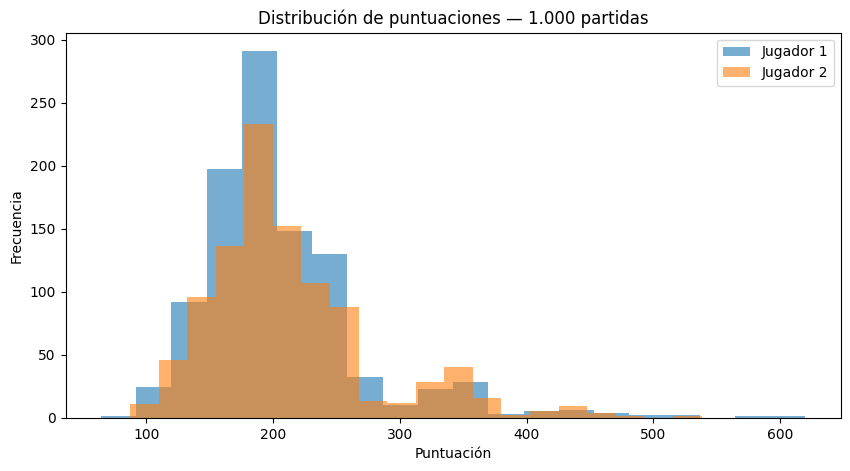

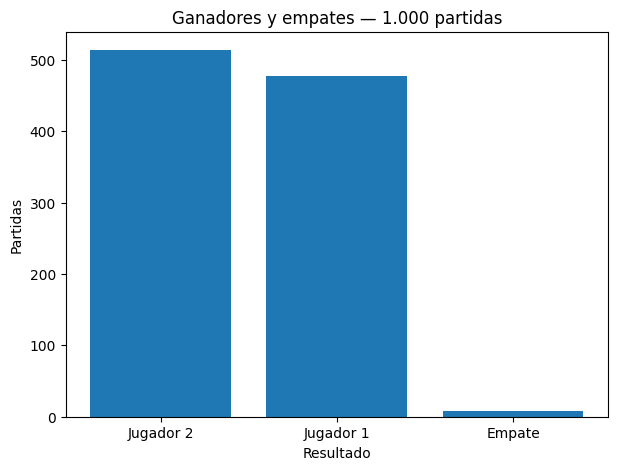

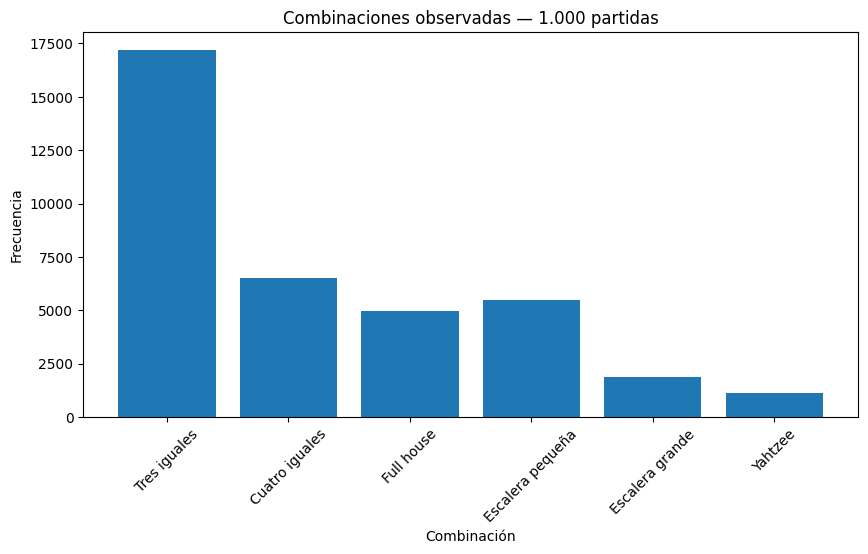

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(df_1000["Puntuación J1"], bins=20, alpha=0.6, label="Jugador 1")
plt.hist(df_1000["Puntuación J2"], bins=20, alpha=0.6, label="Jugador 2")
plt.title("Distribución de puntuaciones — 1.000 partidas")
plt.xlabel("Puntuación")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

plt.figure(figsize=(7, 5))
conteo_resultados = df_1000["Ganador"].value_counts()
plt.bar(conteo_resultados.index, conteo_resultados.values)
plt.title("Ganadores y empates — 1.000 partidas")
plt.xlabel("Resultado")
plt.ylabel("Partidas")
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(
    frecuencias_1000["Combinación"],
    frecuencias_1000["Observada durante lanzamientos"]
)
plt.title("Combinaciones observadas — 1.000 partidas")
plt.xlabel("Combinación")
plt.ylabel("Frecuencia")
plt.xticks(rotation=45)
plt.show()

## 18. Experimento 10.000 partidas

In [ ]:
df_10000, observadas_10000, puntuadas_10000 = ejecutar_montecarlo(
    10000,
    semilla=SEED
)

indicadores_10000 = calcular_indicadores(df_10000)

frecuencias_10000 = tabla_frecuencias(
    observadas_10000,
    puntuadas_10000
)

print("Partidas:", len(df_10000))
display(indicadores_10000.round(3))
display(frecuencias_10000)

Partidas: 10000


,Resultado,Partidas,Porcentaje,Promedio,Mediana,Desviación estándar
0,Jugador 1,4931,49.31,205.446,194.0,61.648
1,Jugador 2,5001,50.01,207.634,195.0,62.775
2,Empate,68,0.68,NaN,NaN,NaN


,Combinación,Observada durante lanzamientos,Utilizada para puntuar
0,Tres iguales,172122,20000
1,Cuatro iguales,65310,20000
2,Full house,49374,20000
3,Escalera pequeña,53823,20000
4,Escalera grande,18262,20000
5,Yahtzee,10725,20000


## 19. Comparación de 1.000 contra 10.000 partidas

El propósito es observar si las estimaciones se vuelven más estables cuando aumentamos el número de experimentos.

In [ ]:
def resumen_experimento(df, nombre):
    return {
        "Experimento": nombre,
        "Partidas": len(df),
        "Victorias J1 (%)": (df["Ganador"] == "Jugador 1").mean() * 100,
        "Victorias J2 (%)": (df["Ganador"] == "Jugador 2").mean() * 100,
        "Empates (%)": (df["Ganador"] == "Empate").mean() * 100,
        "Promedio J1": df["Puntuación J1"].mean(),
        "Promedio J2": df["Puntuación J2"].mean(),
        "Mediana J1": df["Puntuación J1"].median(),
        "Mediana J2": df["Puntuación J2"].median(),
        "Desv. estándar J1": df["Puntuación J1"].std(),
        "Desv. estándar J2": df["Puntuación J2"].std()
    }

comparacion = pd.DataFrame([
    resumen_experimento(df_1000, "1.000 partidas"),
    resumen_experimento(df_10000, "10.000 partidas")
])

display(comparacion.round(3))

,Experimento,Partidas,Victorias J1 (%),Victorias J2 (%),Empates (%),Promedio J1,Promedio J2,Mediana J1,Mediana J2,Desv. estándar J1,Desv. estándar J2
0,1.000 partidas,1000,47.80,51.40,0.80,206.025,211.795,192.5,197.0,64.287,65.985
1,10.000 partidas,10000,49.31,50.01,0.68,205.446,207.634,194.0,195.0,61.648,62.775


## 20. Validación masiva

Ejecutamos partidas independientes adicionales para comprobar las condiciones estructurales del algoritmo.

Esto no sustituye las pruebas unitarias: las complementa.

In [ ]:
def validar_multiples_partidas(cantidad=100):
    for semilla in range(50000, 50000 + cantidad):
        resultado = simular_partida(
            seed=semilla,
            guardar_detalle=True
        )

        assert validar_partida(resultado)

    print(f"✓ {cantidad} partidas adicionales fueron validadas correctamente.")

validar_multiples_partidas(100)

✓ 100 partidas adicionales fueron validadas correctamente.


## 21. Exportación de resultados

Los CSV pueden utilizarse para construir tablas, gráficas o anexarlos como evidencia del experimento.

In [ ]:
df_10000.to_csv("resultados_10000_partidas.csv", index=False)
comparacion.to_csv("comparacion_1000_vs_10000.csv", index=False)
frecuencias_10000.to_csv("frecuencia_combinaciones_10000.csv", index=False)

print("Archivos generados correctamente.")

Archivos generados correctamente.


# 22. Relación entre el algoritmo escrito y el código

| Algoritmo de la actividad | Implementación |
|---|---|
| Crear jugador 1 y jugador 2 | `Jugador("Jugador 1")`, `Jugador("Jugador 2")` |
| Crear tarjetas vacías | `self.tarjeta = {categoria: None ...}` |
| 13 rondas | `for ronda in range(1, 14)` |
| Lanzar cinco dados | `lanzar_cinco_dados()` |
| Estrategia | `aplicar_estrategia_conservar()` |
| Relanzar no conservados | `volver_a_lanzar_no_conservados()` |
| Evaluar combinación | `identificar_combinaciones()` |
| Puntuación | `puntuar_categoria()` |
| Joker | `aplicar_joker()` |
| Registrar categoría | `seleccionar_categoria()` |
| Bonificación superior | `calcular_puntuacion_final()` |
| Comparar puntuaciones | `simular_partida()` |
| Montecarlo | `ejecutar_montecarlo()` |
| 1.000 partidas | `ejecutar_montecarlo(1000, ...)` |
| 10.000 partidas | `ejecutar_montecarlo(10000, ...)` |
| Estadísticas | `calcular_indicadores()` |
| Frecuencia de combinaciones | `tabla_frecuencias()` |
| Reproducibilidad | parámetro `semilla` |

## Resultado

